In [78]:
from pathlib import Path
import os
import zipfile
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

In [4]:
from google.colab import files
files.upload()

Saving dataset.zip to dataset.zip


{'dataset.zip': b'PK\x03\x04\x14\x00\x00\x00\x00\x00\x88e\x8e\\\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0e\x00 \x00dataset_final/UT\r\x00\x07p\x0c\xdeip\x0c\xdeip\x0c\xdeiux\x0b\x00\x01\x04\xf5\x01\x00\x00\x04\x14\x00\x00\x00PK\x03\x04\x14\x00\x08\x00\x08\x00\rf\x8e\\\x00\x00\x00\x00\x00\x00\x00\x00\x048\x00\x00\x17\x00 \x00dataset_final/.DS_StoreUT\r\x00\x07k\r\xdeiP\x0c\xdeik\r\xdeiux\x0b\x00\x01\x04\xf5\x01\x00\x00\x04\x14\x00\x00\x00\xed[kl\x1cW\x19\xbd\xe7\xfa\x91\xd9zb\x8fS\x1b\xdb\xdb\x9ddk\xa7M\xd2n\x9c\xb5\x1d\xc7\xce\x0b\xd6\xaf\xa4\xb1\x93\xd8\xc4v\xfcJ\xeb\xccz\'\xc9$\xeb\x1dwg\xd7v\xea\x06R(E$mQy\x8bW[\x10\x02Z\x11PK \x14hx\xb5\x04\x10B@\xa8\xd4\xf0\x10\x14\x01\x85\x1f<\xd4J\x10\xa8\x10\xdf\xcc\xdcM\xd7k[\x18\xa9\n&\xcc\x91\xc6\x9f\xef\xdc\xc7\xcc7\xf3\x9d\xdd9\xc7c\xc6\x18Z\xd3\xb1:\xc6\xc2\x8c1\x89\xb9Q\x91\xe9\xc7}\x8c\x05\xed\x98\x05Ils\x90G\x1bh\x93\xdd\xdf\x15\xc64v\x98\x19,A\xdb\xe8|\x13r\xc0\xc5\xfc|\xdaJi\xce\xf8\xac\xf9\x1a\xc5\x14K2\x9d\xa2f\xc7\xc9\xde

In [5]:
!unzip dataset.zip
!rm dataset.zip
!ls

Streaming output truncated to the last 5000 lines.
  inflating: dataset_final/imagini_antrenare/E_347.png  
  inflating: dataset_final/imagini_antrenare/F_284.png  
  inflating: dataset_final/imagini_antrenare/I_163.png  
  inflating: dataset_final/imagini_antrenare/4_182.png  
  inflating: dataset_final/imagini_antrenare/E_421.png  
  inflating: dataset_final/imagini_antrenare/E_435.png  
  inflating: dataset_final/imagini_antrenare/4_196.png  
  inflating: dataset_final/imagini_antrenare/I_177.png  
  inflating: dataset_final/imagini_antrenare/2_104.png  
  inflating: dataset_final/imagini_antrenare/E_353.png  
  inflating: dataset_final/imagini_antrenare/F_290.png  
  inflating: dataset_final/imagini_antrenare/1_158.png  
  inflating: dataset_final/imagini_antrenare/F_79.png  
  inflating: dataset_final/imagini_antrenare/F_469.png  
  inflating: dataset_final/imagini_antrenare/A_70.png  
  inflating: dataset_final/imagini_antrenare/A_64.png  
  inflating: dataset_final/imagini_antre

In [6]:
%cd dataset_final
!ls

/content/dataset_final
amprente_digitale  imagini_antrenare  imagini_suspecte	parole


In [7]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [8]:
ROOT = Path('dataset_final')

In [9]:
CHARS = sorted('ABEFOI012478')
LETTERS = set('ABEFOI')
DIGITS = set('012478')
CHAR_TO_IDX = {c: i for i, c in enumerate(CHARS)}
LETTER_IDS = [CHAR_TO_IDX[c] for c in CHARS if c in LETTERS]

In [10]:
CHAR_TO_IDX, LETTER_IDS

({'0': 0,
  '1': 1,
  '2': 2,
  '4': 3,
  '7': 4,
  '8': 5,
  'A': 6,
  'B': 7,
  'E': 8,
  'F': 9,
  'I': 10,
  'O': 11},
 [6, 7, 8, 9, 10, 11])

In [11]:
def read_gray(path):
  with Image.open(path) as im:
    return np.asarray(im.convert('L'), dtype=np.float32)

def rotate(array, angle):
  return np.asarray(Image.fromarray(array.astype(np.float32)).rotate(float(angle), resample=Image.Resampling.BICUBIC, fillcolor=0), dtype=np.float32) # Image.Resampling.BICUBIC for the highest precision

def pad(image):
  assert image.shape == (28, 28)
  return np.pad(image, ((7, 7), (7, 7)))

## Mistake 1
- assigning `dict[character] = ...` inside the image loop discarded the previous 49 estimates. Group the pairs first. Use the filename to obtain the label, not a hard-coded character position in a full path.

In [12]:
!ls dataset_final

ls: cannot access 'dataset_final': No such file or directory


In [13]:
!ls amprente_digitale | head -n 5

0_01.png
0_02.png
0_03.png
0_04.png
0_05.png


In [14]:
!ls

amprente_digitale  imagini_antrenare  imagini_suspecte	parole


In [15]:
%cd dataset_final/

[Errno 2] No such file or directory: 'dataset_final/'
/content/dataset_final


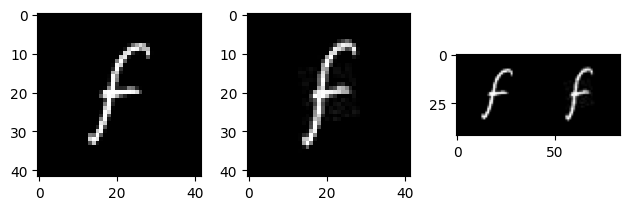

In [16]:
for image in os.listdir('amprente_digitale'):
  path = os.path.join('amprente_digitale', image)
  im = read_gray(path)
  fig, ax = plt.subplots(1, 3)
  ax[0].imshow(im[:, :42], cmap='grey')
  ax[1].imshow(np.stack(im[:, 42:]), cmap='grey')
  ax[2].imshow(np.stack(im[:, :]), cmap='grey')
  plt.tight_layout()
  plt.show()
  break

In [17]:
%cd ..

/content


In [18]:
pairs = {}
for c in CHARS:
  images = [read_gray(p) for p in sorted((ROOT / 'amprente_digitale').glob(f"{c}_*.png"))]
  originals = np.stack([im[:, :42] for im in images]) # Stack them one over another
  transformed = np.stack([im[:, 42:] for im in images]) # Stack them one over another
  pairs[c] = (originals, transformed)

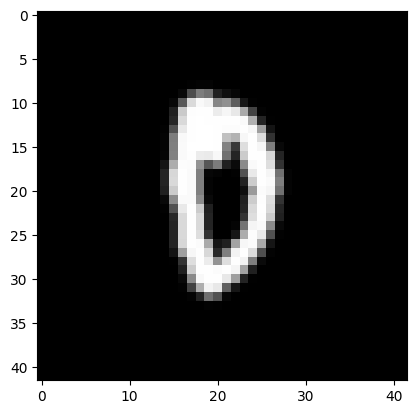

In [19]:
plt.imshow(pairs['0'][0][0], cmap='grey')

In [20]:
for folder in ['imagini_antrenare', 'imagini_suspecte', 'parole']:
  paths = sorted((ROOT / folder).glob('*.png'))
  shapes = sorted({read_gray(p).shape for p in paths})
  print(folder, len(paths), shapes)

imagini_antrenare 6000 [(28, 28)]
imagini_suspecte 200 [(42, 42)]
parole 300 [(42, 126), (42, 210), (42, 294)]


In [21]:
paths[0]

PosixPath('dataset_final/parole/task4_000.png')

## Estimate the forward angle

- My mistake was that rotating the corrupted image back estimates the opposite sign; range(-30, 30) omits +30;
one font is noisy evidence. Here we rotate originals toward corrupted images and average over all calibration pairs

In [22]:
def angle_error(originals, transformed, angle):
  predictions = np.stack([np.clip(rotate(im, angle), 0, 255) for im in originals])
  return np.abs(predictions - transformed).mean()

angles = {}
coarse = np.arange(-30, 31, dtype=int)
for c, (originals, transformed) in pairs.items():
  angles[c] = int(min(coarse, key=lambda a: angle_error(originals, transformed, a)))

  print(c, angles[c])

0 15
1 9
2 -30
4 -27
7 -24
8 10
A -8
B -30
E 16
F 5
I 10
O -28


## Estimate signed noise in the forward model

- **Our mistake** was that `ImageChops.difference` takes absolute values, so negative noise is lost; cropping before undoing rotation discards pixels; clipping means ordinary subtraction is not an exact inverse.

Instead, fit a signed 28x28 noise matrix using the known forward operations: **add -> clip -> pad -> rotate**. The rotation matrix below is just the same rotation applied to each one-pixel basis image. Noise is constrained to [-25, 25]. Pixels whose noise cannot be identified get a small preference toward zero. This remains an approximation to the generator's interpolation and quantization.

In [23]:
def rot_mat(angle):
  columns = []
  for pixel in range(28*28):
    basis = np.zeros((28, 28), dtype=np.float32)
    basis.flat[pixel] = 1 # A single white pixel at that position, "standard basis vector" e_i in linalg
    columns.append(rotate(pad(basis), angle).ravel()) # Adds padding so it doesn't get clipped during rotation, and then flattens the 2D grid back into a 1D array
  return csr_matrix(np.stack(columns, axis=1)) # csr_matrix = Compressed Sparse Row matrix (in SciPy lib) | This is used in order to save an immense amount of memory (storing only the non-zero values)

### How it is used:

Once you compute this matrix by calling R = rot_mat(30), you no longer need to use slow image processing libraries to rotate your 28x28 images.
If you have a flat image vector x (length 784), you can rotate it instantly using a single dot product:
$$Rotated \space Image=R \times x$$
Because the operation is reduced to a `sparse matrix multiplication`, it runs incredibly fast, making it ideal for Machine Learning pipelines or mathematical optimizations.

In [24]:
def fit_noise(originals, transformed, angle):
  operator = rot_mat(angle)
  clean = originals[:, 7:35, 7:35].reshape(-1, 784).astype(np.float64) # take only the central region of the image via the central slicing | the reshape part makes it a vector (1D array)
  target = transformed.reshape(-1, 1764).astype(np.float64) # processes the already transformed images in a 1D linear vector of 1764 elements

  def objective(noise):
    before_clip = clean + noise[None, :]
    corrupted = np.clip(before_clip, 0, 255)
    rotated = (operator @ corrupted.T).T
    prediction = np.clip(rotated, 0, 255)
    residual = prediction - target
    value = np.mean(residual**2) + 1e-5 * np.mean(noise**2)
    gradient_output = 2 * residual / residual.size
    gradient_output *= (rotated > 0) & (rotated < 255) # Nulls if the newly obtained rotated matrix is 0 < rot_mat < 255
    gradient_input = (operator.T @ gradient_output.T).T
    gradient_input *= (before_clip > 0) & (before_clip < 255)
    gradient = gradient_input.sum(axis=0) + 2e-5 * noise / noise.size
    return value, gradient

  # Starting away from exactly zero avoids clipping-boundary zero gradients
  initial = np.ones(784, dtype=np.float64)
  result = minimize(objective, initial, jac=True, method='L-BFGS-B', bounds=[(-25, 25)] * 784, options={'maxiter': 150, 'ftol': 1e-10})
  if not result.success:
    print('Noise optimizer:', result.message)
  return result.x.reshape(28, 28).astype(np.float32)

noise = {}
for c, (originals, transformed) in pairs.items():
  noise[c] = fit_noise(originals, transformed, angles[c])
  print(c, '|', 'noise range:', noise[c].min().round(2), 'to', noise[c].max().round(2))

0 | noise range: -25.0 to 24.47
1 | noise range: -25.0 to 24.46
2 | noise range: -25.0 to 24.69
4 | noise range: -25.0 to 24.64
7 | noise range: -25.0 to 24.67
8 | noise range: -25.0 to 24.53
A | noise range: -25.0 to 24.53
Noise optimizer: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
B | noise range: -25.0 to 24.71
E | noise range: -25.0 to 24.55
F | noise range: -25.0 to 22.53
I | noise range: -25.0 to 24.46
O | noise range: -25.0 to 24.63


In [25]:
def corrupt(clean, c):
  noisy = np.clip(clean.astype(np.float32) + noise[c], 0, 255)
  return np.clip(rotate(pad(noisy), angles[c]), 0, 255)

fingerprints = {c: {'angle': angles[c], 'noise': noise[c]} for c in CHARS}
np.save('amprente_digitale.npy', fingerprints, allow_pickle=True)

In [26]:
!ls

amprente_digitale.npy  dataset_final  __MACOSX	sample_data


In [27]:
files.download('amprente_digitale.npy')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Check reconstruction before using the estimates

- **My mistake:** I submitted the estimates without checking whether they could reproduce the observed corruption. These are reconstructed diagnostics, not ground-truth angle/noise errors.

0 reconstruction MAE: 0.047


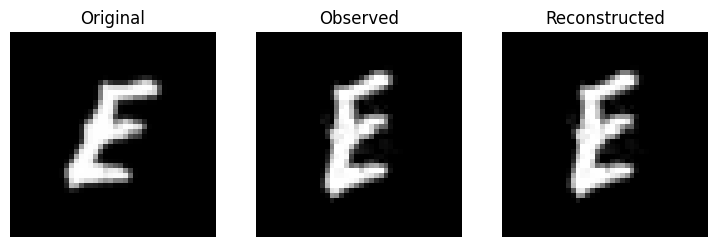

1 reconstruction MAE: 0.03


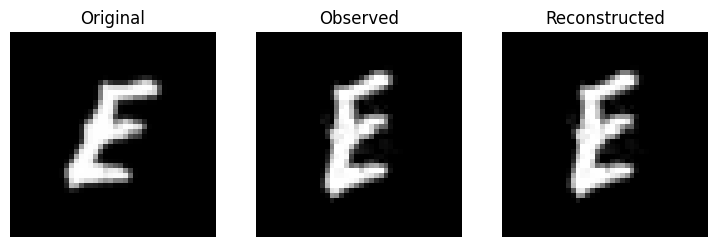

2 reconstruction MAE: 0.043


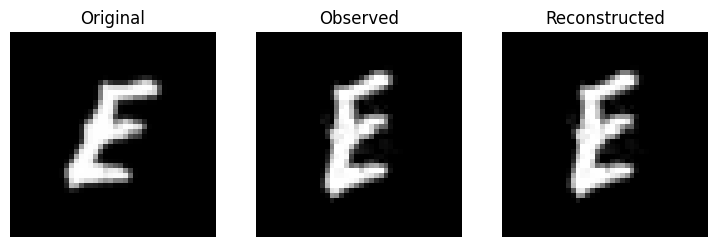

4 reconstruction MAE: 0.041


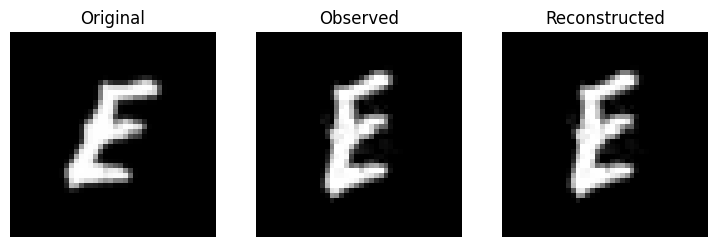

7 reconstruction MAE: 0.039


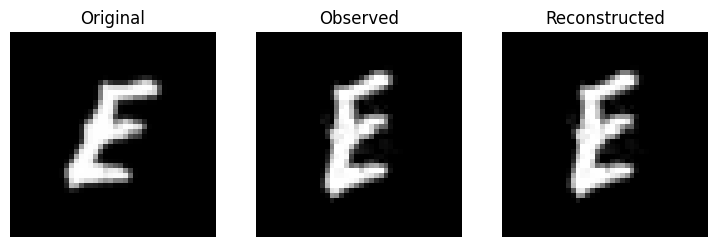

8 reconstruction MAE: 0.043


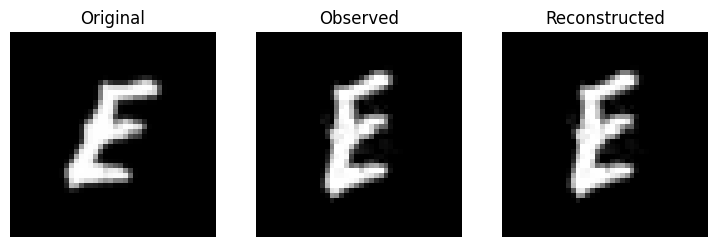

A reconstruction MAE: 0.042


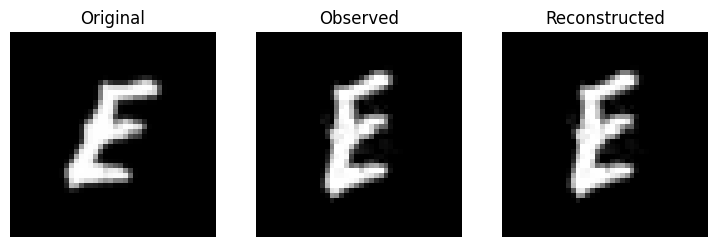

B reconstruction MAE: 0.047


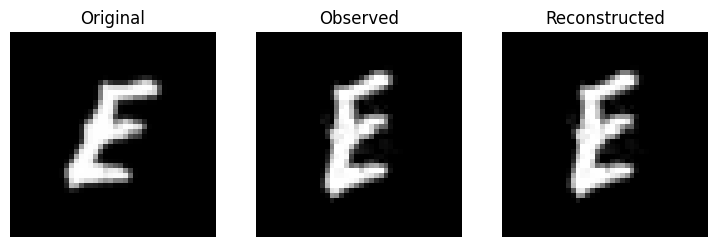

E reconstruction MAE: 0.045


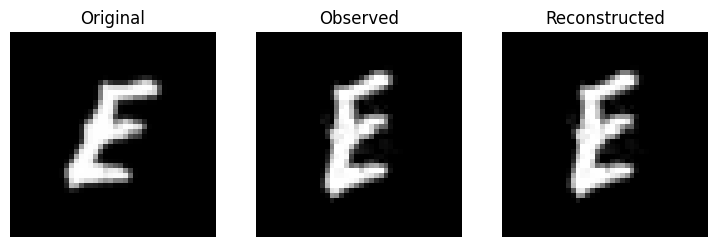

F reconstruction MAE: 0.039


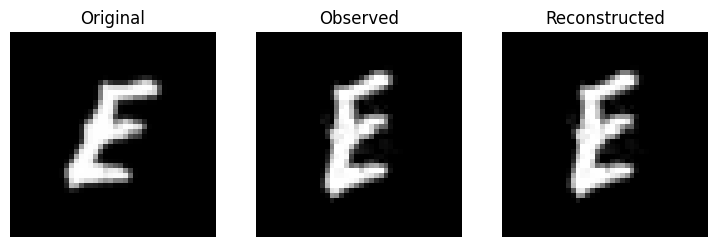

I reconstruction MAE: 0.035


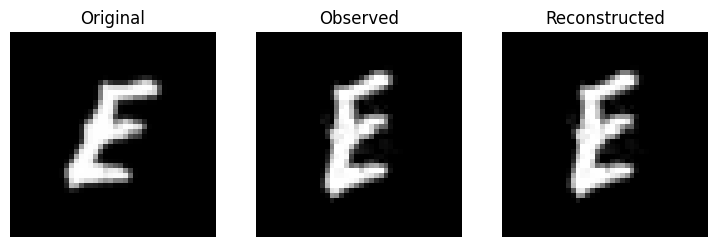

O reconstruction MAE: 0.047


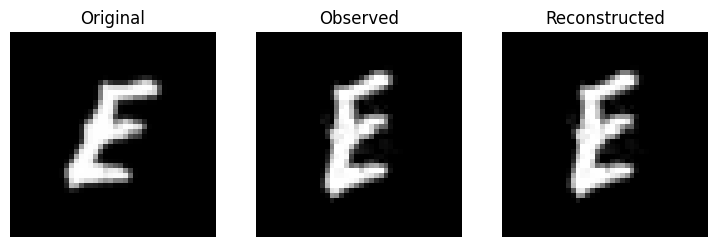

In [28]:
for c, (originals, transformed) in pairs.items():
  reconstructed = np.stack([corrupt(im[7:35, 7:35], c) for im in originals])
  print(c, 'reconstruction MAE:', round(float(np.abs(reconstructed - transformed).mean()), 3))

  c = 'E' # example
  originals, transformed = pairs[c]
  fig, axes = plt.subplots(1, 3, figsize=(9,3))
  for ax, image, title in zip(axes, [originals[0], transformed[0], corrupt(originals[0, 7:35, 7:35], c)], ['Original', 'Observed', 'Reconstructed']):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
  plt.show()


## Build a validation split and match train/test geometry

**My mistakes:** training on clean 28x28 characters while testing on corrupted 42x42 canvases creates a distribution mismatch. Horizontal flips create unrealistic characters and do not simulate the fault. We apply the estimated character-specific corruption and keep every input at 42x42. Split clean images before transforming them.

In [29]:
!ls dataset_final/imagini_antrenare/ | tail -5
!ls dataset_final/imagini_antrenare/ | head -5

O_95.png
O_96.png
O_97.png
O_98.png
O_99.png
0_01.png
0_02.png
0_03.png
0_04.png
0_05.png


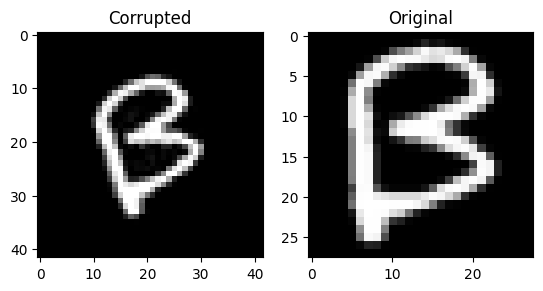

In [30]:
for image in os.listdir('dataset_final/imagini_antrenare'):
    path = os.path.join('dataset_final/imagini_antrenare', image)
    fig, ax = plt.subplots(1, 2)
    ax[0].imshow(corrupt(read_gray(path), '0'), cmap='gray')
    ax[1].imshow(read_gray(path), cmap='gray')
    ax[0].set_title('Corrupted')
    ax[1].set_title('Original')
    break

In [31]:
clean_paths = sorted((ROOT/'imagini_antrenare').glob('*.png'))
clean_labels = [p.stem.split('_')[0] for p in clean_paths]
clean_labels[:5]

['0', '0', '0', '0', '0']

In [32]:
train_paths, valid_paths = train_test_split(clean_paths, test_size=0.20, random_state=SEED, stratify=clean_labels)

In [33]:
class CharacterDataset(Dataset):
  def __init__(self, paths):
    self.images = []
    self.labels = []
    i = 0
    for path in paths:
      i+=1
      c = path.stem.split('_')[0] # character is the first char in the path | Alt: c = path[0]
      image = corrupt(read_gray(path), c)
      self.images.append(image[None, :, :] / 255.0) # / 255.0 is for normalization 0-1
      # if i % 2399 == 0:
      #   plt.imshow((image[None, :, :] / 255.0).squeeze(), cmap='gray')
      self.labels.append(CHAR_TO_IDX[c])
    print(i)
    self.images = torch.from_numpy(np.stack(self.images)).float()
    self.labels = torch.tensor(self.labels, dtype=torch.long)

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, idx):
    return self.images[idx], self.labels[idx]

train_data = CharacterDataset(train_paths)
valid_data = CharacterDataset(valid_paths)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(valid_data, batch_size=128, shuffle=False)

4800
1200


### The Model will be a 3 layer convolutional network simple feedforward network (no residuals - `x_new = f(x) + x`) followed by a dropout layer

In [34]:
class CharacterCNN(nn.Module):
  def __init__(self):
    super().__init__()
    """Initial size: [1, 42, 42]"""
    self.layers = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.GELU(), nn.MaxPool2d(2), # [32, 20, 20]
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.GELU(), nn.MaxPool2d(2), # [64, 10, 10]
        nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.GELU(), nn.MaxPool2d(2), # [128, 5, 5]
        nn.Flatten(), nn.Linear(128*5*5, 128), nn.GELU(), # nn.Linear(128*5*5, 128) hence the final dimension of the tensor at the end of the network
        nn.Dropout(0,2), nn.Linear(128, len(CHARS)), # Outputs logits
    )

  def forward(self, x):
    return self.layers(x)

model = CharacterCNN().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
crit = nn.CrossEntropyLoss()

## Train, validate, and retain the best checkpoint
**My mistake:** training loss alone cannot choose a checkpoint or tell whether the model generalizes.
Explicit `train()` / `eval()` calls also make rerunning notebooks cells safe. Loss is averaged using the actual number of examples, rather than dividing the first single batch by 16.

In [40]:
best_acc = -1
best_weights = None
EPOCHS = 15
for epoch in range(EPOCHS):
  model.train()
  total_loss = 0.0
  for images, labels in train_loader:
    images, labels = images.to(DEVICE), labels.to(DEVICE)
    optimizer.zero_grad(set_to_none=True)
    logits = model(images)
    loss = crit(logits, labels)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * len(labels)

  model.eval()
  correct = 0
  with torch.inference_mode():
    for images, labels in val_loader:
      predictions = model(images.to(DEVICE)).argmax(dim=1).cpu()
      correct += (predictions == labels).sum().item()

  accuracy = correct / len(valid_data)
  if accuracy > best_acc:
    best_acc = accuracy
    best_weights = copy.deepcopy(model.state_dict())
  print(f"Epoch {epoch + 1:02d}: loss={total_loss / len(train_data):.4f}, "
    f"validation accuracy={accuracy:.3%}")

model.load_state_dict(best_weights)
model.eval()
print("Best val. accuracy:", best_acc)

"""Function to be applied on a stack of images, which we get from Paths iterated and outputted from read_gray()"""
@torch.inference_mode()
def predict_probabilities(images):
  model.eval()

  arrays = np.stack(images).astype(np.float32)  # (N, 42, 42)
  tensor = torch.from_numpy(arrays).unsqueeze(1) / 255.0
  # tensor: (N, 1, 42, 42)

  probabilities = []

  for batch in tensor.split(128):
      logits = model(batch.to(DEVICE))         # (batch_size, 12)
      probs = logits.softmax(dim=1)
      probabilities.append(probs.cpu().numpy())

  return np.concatenate(probabilities, axis=0) # (N, 12)


Epoch 01: loss=0.0248, validation accuracy=96.833%
Epoch 02: loss=0.0087, validation accuracy=97.167%
Epoch 03: loss=0.0108, validation accuracy=97.583%
Epoch 04: loss=0.0044, validation accuracy=96.583%
Epoch 05: loss=0.0076, validation accuracy=97.500%
Epoch 06: loss=0.0030, validation accuracy=97.417%
Epoch 07: loss=0.0009, validation accuracy=97.583%
Epoch 08: loss=0.0015, validation accuracy=97.750%
Epoch 09: loss=0.0127, validation accuracy=97.167%
Epoch 10: loss=0.0031, validation accuracy=97.417%
Epoch 11: loss=0.0012, validation accuracy=97.583%
Epoch 12: loss=0.0003, validation accuracy=97.500%
Epoch 13: loss=0.0002, validation accuracy=97.500%
Epoch 14: loss=0.0002, validation accuracy=97.500%
Epoch 15: loss=0.0001, validation accuracy=97.417%
Best val. accuracy: 0.9775


### inference_mode - Source: [PyTorch docs](https://docs.pytorch.org/docs/2.15/generated/torch.autograd.grad_mode.inference_mode.html)
class `torch.autograd.grad_mode.inference_mode(mode=True)`

**[source]**

Context manager that enables or disables inference mode.

InferenceMode is analogous to no_grad and should be used when you are certain your operations will not interact with autograd (e.g., during data loading or model evaluation). Compared to no_grad, it removes additional overhead by disabling view tracking and version counter bumps. It is also more restrictive, in that tensors created in this mode cannot be used in computations recorded by autograd.

This context manager is thread-local; it does not affect computation in other threads.

Also functions as a decorator.

## Mission 3: rejection is a separate decision
**My mistake:** a 12-class softmax is not a probability that an image is valid; an unseen character can still receive high confidence. Your 0.80 cutoff was not validated.

If you have **permitted, labeled invalid validation images,** place them in `invalid_validation/` (each 42×42 and representative of test corruption). The code then chooses a threshold by balanced accuracy. Without them, it chooses a threshold retaining approximately 95% of held-out valid samples and prints a warning: this controls valid rejection only, not invalid acceptance. It is a transparent fallback, not a solved open-set detector. Synthetic-valid validation may also differ from real corruption.

In [44]:
!ls

amprente_digitale.npy  dataset_final  __MACOSX	sample_data


In [57]:
valid_images = [corrupt(read_gray(p), p.stem.split('_')[0]) for p in valid_paths]
valid_confidence = predict_probabilities(valid_images).max(axis=1)
threshold = float(np.quantile(valid_confidence, 0.05))

suspect_paths = sorted((ROOT / 'imagini_suspecte').glob("*.png"))
suspect_probabilities = predict_probabilities([read_gray(p) for p in suspect_paths])
suspect_predictions = (suspect_probabilities.max(axis=1) >= threshold).astype(int)
print(len(suspect_predictions))
print(len(suspect_paths))
mission3 = pd.DataFrame({
    'file': [p.name for p in suspect_paths],
    'subtaskID': 3,
    'class': suspect_predictions,
})

200
200


## Mission 4: split -> classify -> majority

**My mistake:** resizing the whole password to 28x28 and predicting one character destroys the sequence. Our files are 42 pixels tall and 126, 210, or 294 pixels wide: exactly 3, 5, or 7 adjacent 42x42 character cells. No segmentation model is needed. Classify each cell and vote

In [60]:
!ls dataset_final/parole | head -5

task4_000.png
task4_001.png
task4_002.png
task4_003.png
task4_004.png


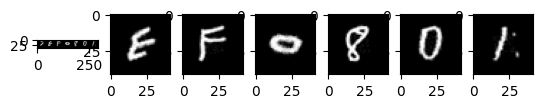

In [75]:
def split_password(image):
  if hasattr(image, 'size'):
    image = np.array(image)
  H, W = image.shape
  assert H == 42 and W % 42 == 0
  count = W // 42
  assert count in (3, 5, 7)
  return [image[:, 42 * i:42 * (i+1)] for i in range(count)]

for image in os.listdir('dataset_final/parole'):
  path = os.path.join('dataset_final/parole', image)
  with Image.open(path) as im:
    fig, ax = plt.subplots(1, 7)
    ax[0].imshow(im, cmap='gray')
    for i in range(1, 7):
      ax[i].imshow(split_password(im)[i], cmap='gray')
  break

In [76]:
password_paths = sorted((ROOT / 'parole').glob("*.png"))
password_tiles = [split_password(read_gray(p)) for p in password_paths]
all_tiles = [tile for tiles in password_tiles for tile in tiles]
all_predictions = predict_probabilities(all_tiles).argmax(axis=1)

password_labels = []
offset = 0
for tiles in password_tiles:
  predictions = all_predictions[offset:offset + len(tiles)]
  letter_count = sum(CHARS[int(index)] in LETTERS for index in predictions)
  password_labels.append('letters' if letter_count > len(tiles) // 2 else 'digits')
  offset += len(tiles)
assert offset == len(all_predictions)

mission4 = pd.DataFrame({
    "file": [p.name for p in password_paths],
    "subtaskID": 4,
    "class": password_labels,
})
print(mission4.head())

            file  subtaskID    class
0  task4_000.png          4   digits
1  task4_001.png          4  letters
2  task4_002.png          4   digits
3  task4_003.png          4   digits
4  task4_004.png          4  letters


In [79]:
submission = pd.concat([mission3, mission4], ignore_index=True)
assert len(mission3) == 200 and len(mission4) == 300
assert not submission.duplicated(["file", "subtaskID"]).any()
assert set(fingerprints) == set(CHARS)
assert all(v["noise"].shape == (28, 28) for v in fingerprints.values())
assert all(np.isfinite(v["noise"]).all() for v in fingerprints.values())
submission.to_csv("parole.csv", index=False)
with zipfile.ZipFile('submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
  z.write('amprente_digitale.npy', arcname='amprente_digitale.npy')
  z.write('parole.csv', arcname='parole.csv')

files.download('submission.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>